# Temporal CNN Bigru (Scoliosis1K)

**Paper Reference:** Table 3, Row 1 (Accuracy: 45.5%, Sensitivity: 99.0%, Specificity: 27.0%).

**Paper Definition of Baseline CNN:**
> *"A basic model trained with cross-entropy loss, excluding horizontal pooling and BNNeck."*

**Implementation Choices to Match Paper:**
- **Backbone**: OpenGait `ResNet9` (channels `[64, 128, 256, 512]`, strides `[1, 2, 2, 1]`).
- **Temporal Aggregation**: Temporal Max Pooling (TP) over frames.
- **Head**: Global Average Pooling -> Linear(512, 256) -> Linear(256, 3). *No BNNeck, no scale=16.*
- **Loss**: Cross-Entropy only. Label smoothing 0.1 (OpenGait default).
- **Optimizer**: SGD, LR 0.1, Momentum 0.9, Weight Decay 0.0005. Milestones at 10k, 14k, 18k.
- **Data Pipeline**: `TripletSampler` (8 identities x 8 sequences) over the 1:1:8 split from `Scoliosis1K_118.json`.

**Expected Results Note**: The test set is heavily skewed toward Positive (419 out of 749). Blind guessing "Positive" yields ~56% accuracy. The paper's Baseline CNN achieving 45.5% is expected for a CE-only model without triplet identity supervision. It is completely normal if your reproduced accuracy lands in the 40-55% range.

In [1]:
import os
# Mencegah fragmentasi memori GPU agar tidak OOM
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import copy, json, pickle, random, time
from functools import lru_cache
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ==========================================
# 1. SETTINGS
# ==========================================
DATASET_ROOT = Path("/mnt/home/probation-01/kelompok8/OpenGait-ScoNet/datasets/Scoliosis1K-sil-pkl") 
PARTITION_JSON = Path("/mnt/home/probation-01/kelompok8/OpenGait-ScoNet/datasets/Scoliosis1K/Scoliosis1K_118.json")

LABELS = ["negative", "neutral", "positive"]
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}
NUM_CLASSES = 3
N_FRAMES = 30

# Paper Hyperparameters
TOTAL_ITERS = 20000
MILESTONES = [10000, 14000, 18000]
TRAIN_LR = 0.01
IDS_PER_BATCH = 8
SEQS_PER_ID = 8
LABEL_SMOOTHING = 0.1

SEED = 0
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE} | PyTorch: {torch.__version__}")

# ==========================================
# 2. DATA LOADING & PREPROCESSING
# ==========================================
def load_pkl(path):
    with open(path, "rb") as f:
        seq = np.asarray(pickle.load(f))
    if seq.ndim == 4 and seq.shape[1] == 1:
        seq = seq[:, 0]
    elif seq.ndim == 4 and seq.shape[-1] == 1:
        seq = seq[..., 0]
    return seq

def cut_and_normalize(seq):
    cut = seq.shape[-1] // 64 * 10
    if cut > 0:
        seq = seq[..., cut:-cut]
    return seq.astype(np.float32) / 255.0

def random_clip(seq, n_frames=N_FRAMES):
    idx = np.random.choice(len(seq), n_frames, replace=len(seq) < n_frames)
    return seq[idx]

def train_clip(seq, n_frames=N_FRAMES):
    return cut_and_normalize(random_clip(seq, n_frames))

@lru_cache(maxsize=None)
def load_pkl_cached(path):
    return load_pkl(path)

def build_index(root, subject_ids):
    items = []
    for sid in subject_ids:
        folder = root / str(sid)
        if not folder.is_dir(): continue
        for pkl in sorted(folder.rglob("*.pkl")):
            names = [p.lower() for p in pkl.relative_to(root).parts[:-1]]
            class_id = next((LABEL_TO_ID[n] for n in names if n in LABEL_TO_ID), None)
            if class_id is not None:
                items.append((str(sid), class_id, pkl))
    return items

def make_triplet_batch_fn(items, ids_per_batch, seqs_per_id):
    """BALANCED SAMPLER: Mengambil subjek secara seimbang (Pos, Neu, Neg) per batch."""
    by_subject = {}
    for sid, class_id, path in items:
        by_subject.setdefault(sid, []).append((class_id, path))
    
    subjects_by_class = {0: [], 1: [], 2: []}
    for sid, seqs in by_subject.items():
        cid = seqs[0][0] 
        subjects_by_class[cid].append(sid)
        
    index = {sid: i for i, sid in enumerate(by_subject.keys())}

    def get_batch():
        clips, ids, classes = [], [], []
        # 3 Pos, 3 Neu, 2 Neg (Total 8 subjek = 64 gambar per iterasi)
        class_quota = {2: 3, 1: 3, 0: 2} 
        
        for cid, quota in class_quota.items():
            pool = subjects_by_class[cid]
            num_to_pick = min(quota, len(pool))
            
            if num_to_pick > 0:
                chosen_sids = random.sample(pool, num_to_pick)
                for sid in chosen_sids:
                    seq_pool = by_subject[sid]
                    if len(seq_pool) >= seqs_per_id:
                        picks = random.sample(seq_pool, seqs_per_id)
                    else:
                        picks = random.choices(seq_pool, k=seqs_per_id)
                        
                    for class_id, path in picks:
                        clips.append(train_clip(load_pkl_cached(path)))
                        ids.append(index[sid])
                        classes.append(class_id)
                        
        return np.stack(clips), np.array(ids), np.array(classes)
    return get_batch

Device: cuda | PyTorch: 2.15.0+cu132


In [2]:
# ==========================================
# 3. TEMPORAL CNN + TCN ARCHITECTURE
# ==========================================
class TemporalBlock(nn.Module):
    """Satu blok TCN: Conv1d (dilated) -> BN -> ReLU -> Dropout."""
    def __init__(self, in_ch, out_ch, kernel_size=3, dilation=1, dropout=0.1):
        super().__init__()
        padding = (kernel_size - 1) * dilation // 2
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size, padding=padding, dilation=dilation)
        self.bn = nn.BatchNorm1d(out_ch)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.relu(self.bn(self.conv(x))))


class TCN(nn.Module):
    """TCN dengan 4 blok dilation [1,2,4,8]. Receptive field = 31 frame."""
    def __init__(self, in_ch=128, out_ch=256, dropout=0.1):
        super().__init__()
        self.blocks = nn.ModuleList([
            TemporalBlock(in_ch, out_ch, kernel_size=3, dilation=1, dropout=dropout),
            TemporalBlock(out_ch, out_ch, kernel_size=3, dilation=2, dropout=dropout),
            TemporalBlock(out_ch, out_ch, kernel_size=3, dilation=4, dropout=dropout),
            TemporalBlock(out_ch, out_ch, kernel_size=3, dilation=8, dropout=dropout),
        ])

    def forward(self, x):
        for block in self.blocks:
            x = block(x)
        return x


class TemporalCNN(nn.Module):
    def __init__(self, num_classes=3, feat_dim=256):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1, 1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, 1, 1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, 1, 1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.tcn = TCN(in_ch=128, out_ch=256, dropout=0.1)
        self.embedding = nn.Sequential(
            nn.Linear(256, feat_dim),
            nn.BatchNorm1d(feat_dim),
            nn.ReLU(),
            nn.Dropout(0.5)
        )
        self.classifier = nn.Linear(feat_dim, num_classes)
        self.centers = nn.Parameter(torch.randn(num_classes, feat_dim))

    def forward(self, sils):
        n, s, h, w = sils.shape
        x = sils.view(n * s, 1, h, w)
        x = self.backbone(x)
        x = x.view(n, s, -1)          # [n, 30, 128]
        x = x.transpose(1, 2)          # [n, 128, 30]
        x = self.tcn(x)                # [n, 256, 30]
        x = x.mean(dim=2)              # [n, 256]

        embed = self.embedding(x)
        logits = self.classifier(embed)
        return embed.unsqueeze(-1), logits.unsqueeze(-1)


def init_weights(m):
    if isinstance(m, (nn.Conv1d, nn.Conv2d)):
        nn.init.xavier_uniform_(m.weight)
    elif isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d)) and m.affine:
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


def make_model():
    model = TemporalCNN()
    model.apply(init_weights)
    return model.to(DEVICE)

In [3]:
# ==========================================
# 4. TRAINING LOOP (CE + FOCAL + CENTER)
# ==========================================
class FocalLoss(nn.Module):
    def __init__(self, alpha=1, gamma=2, label_smoothing=0.1):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, classes):
        ce_loss = F.cross_entropy(logits, classes, reduction='none', label_smoothing=self.label_smoothing)
        pt = torch.exp(-ce_loss)
        focal_loss = self.alpha * (1 - pt) ** self.gamma * ce_loss
        return focal_loss.mean()


def compute_loss(logits, embed, classes, centers):
    logits_flat = logits.mean(-1)
    loss_ce = F.cross_entropy(logits_flat, classes, label_smoothing=0.1)

    focal = FocalLoss()
    loss_focal = focal(logits_flat, classes)

    embed_flat = embed.mean(-1)
    batch_centers = centers[classes]
    loss_center = torch.mean(torch.sum((embed_flat - batch_centers) ** 2, dim=1))

    total_loss = loss_ce + (0.5 * loss_focal) + (0.05 * loss_center)
    return total_loss, loss_ce


def save_checkpoint(path, model, optimizer, scheduler, scaler, it, history):
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                "iter": it, "history": history}, path)


def train(model, get_batch, iters, lr=0.01, milestones=(), log_every=100, amp=True,
          label_smoothing=0.1, ckpt_path=None, save_every=5000):
    amp = amp and DEVICE.type == "cuda"

    # SGD sesuai config, dan tcn.parameters() WAJIB masuk optimizer
    optimizer = torch.optim.SGD([
        {'params': model.backbone.parameters()},
        {'params': model.tcn.parameters()},           # <-- fix blocker #1
        {'params': model.embedding.parameters()},
        {'params': model.classifier.parameters()},
        {'params': model.centers, 'lr': lr * 1}
    ], lr=lr, momentum=0.9, weight_decay=5e-4)

    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=list(milestones), gamma=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=amp)

    history = {"ce": [], "acc": [], "lr": []}
    t0 = time.time()

    for it in range(1, iters + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)

        sils, ids, classes = get_batch()
        sils = torch.as_tensor(sils, dtype=torch.float32, device=DEVICE)
        classes = torch.as_tensor(classes, dtype=torch.long, device=DEVICE)

        accum_steps = 2
        chunk_size = 32
        total_loss_val = 0.0
        total_acc = 0.0
        skip_iter = False

        for i in range(accum_steps):
            sils_chunk = sils[i*chunk_size : (i+1)*chunk_size]
            classes_chunk = classes[i*chunk_size : (i+1)*chunk_size]

            # fp16 sesuai config (bukan bf16)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
                embed, logits = model(sils_chunk)

            logits = logits.float()
            embed = embed.float()

            loss, _ = compute_loss(logits, embed, classes_chunk, model.centers)

            # Guard NaN sebelum backward
            if not torch.isfinite(loss):
                print(f"iter {it} chunk {i}: loss tidak finite, skip iter")
                skip_iter = True
                break
            scaled_loss = scaler.scale(loss / accum_steps)
            scaled_loss.backward()
            total_loss_val += loss.item() / accum_steps
            total_acc += (logits.mean(-1).argmax(1) == classes_chunk).float().mean().item() / accum_steps

        if skip_iter:
            optimizer.zero_grad(set_to_none=True)
            continue

        scaler.unscale_(optimizer)
        # max_norm=5.0 sesuai config
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)

        scale_before = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        scale_after = scaler.get_scale()

        history["lr"].append(optimizer.param_groups[0]['lr'])

        if scale_before == scale_after:
            scheduler.step()

        history["ce"].append(total_loss_val)
        history["acc"].append(total_acc)

        if it == 1 or it % log_every == 0 or it in milestones:
            elapsed = time.time() - t0
            eta = elapsed / it * (iters - it)
            lr_now = optimizer.param_groups[0]['lr']
            print(f"iter {it:5d} | LR {lr_now:.2e} | Loss {total_loss_val:.4f} | acc {total_acc:.2f} | ETA {eta/60:.1f}m")

        if ckpt_path and save_every and (it % save_every == 0 or it == iters):
            save_checkpoint(ckpt_path, model, optimizer, scheduler, scaler, it, history)
    return history

In [4]:
# ==========================================
# 5. EVALUATION & VISUALIZATION
# ==========================================
@torch.no_grad()
def predict(model, seq_uint8, max_frames=720):
    model.eval()
    seq_uint8 = seq_uint8[:max_frames]
    x = torch.from_numpy(cut_and_normalize(seq_uint8)).unsqueeze(0).to(DEVICE)
    _, logits = model(x)
    scores = logits.mean(-1)
    probs = torch.softmax(scores, dim=-1)[0].cpu().numpy()
    return int(probs.argmax()), probs

def confusion(model, items, max_frames=720):
    conf = np.zeros((3, 3), dtype=int)
    for _, class_id, path in items:
        pred, _ = predict(model, load_pkl_cached(path), max_frames)
        conf[class_id, pred] += 1
    return conf

def paper_metrics(conf):
    accuracy = conf.trace() / max(conf.sum(), 1)
    sensitivity = conf[0, 0] / max(conf[0].sum(), 1) 
    specificity = conf[1:, 1:].sum() / max(conf[1:].sum(), 1) 
    return accuracy, sensitivity, specificity

def plot_all(history, conf, acc, sen, spe):
    # Mengubah menjadi 4 panel (figsize lebih lebar)
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))
    
    # 1. Loss Curve
    axes[0].plot(history["ce"], color='tab:blue', alpha=0.8)
    axes[0].set_title("Training Loss (Total)")
    axes[0].set_xlabel("Iteration")
    axes[0].grid(True, alpha=0.3)

    # 2. Accuracy Curve (BARU!)
    axes[1].plot(history["acc"], color='tab:green', alpha=0.8)
    axes[1].set_title("Training Accuracy")
    axes[1].set_xlabel("Iteration")
    axes[1].set_ylim(0, 1.05)
    axes[1].grid(True, alpha=0.3)

    # 3. Learning Rate Schedule
    axes[2].plot(history["lr"], color='tab:red')
    axes[2].set_title("Learning Rate Schedule")
    axes[2].set_xlabel("Iteration")
    axes[2].set_yscale('log')
    axes[2].grid(True, alpha=0.3)

    # 4. Confusion Matrix
    im = axes[3].imshow(conf, cmap="Blues")
    for i in range(3):
        for j in range(3):
            axes[3].text(j, i, conf[i, j], ha="center", va="center", 
                         color="white" if conf[i, j] > conf.max() / 2 else "black")
    axes[3].set_xticks([0, 1, 2])
    axes[3].set_yticks([0, 1, 2])
    axes[3].set_xticklabels(LABELS)
    axes[3].set_yticklabels(LABELS)
    axes[3].set_xlabel("Predicted")
    axes[3].set_ylabel("True")
    axes[3].set_title(f"Confusion Matrix\nAcc: {acc:.1%} | Sen: {sen:.1%} | Spe: {spe:.1%}")
    fig.colorbar(im, ax=axes[3], fraction=0.046)
    
    plt.tight_layout()
    plt.show()

def evaluate(model, items, history):
    conf = confusion(model, items)
    acc, sen, spe = paper_metrics(conf)
    print(f"\nAccuracy: {acc:.1%} | Sensitivity: {sen:.1%} | Specificity: {spe:.1%}")
    plot_all(history, conf, acc, sen, spe)

Train sequences: 744 | Test sequences: 749
Total parameters: 852,163 | TCN parameters: 691,200

Starting training: 20000 iters, 8x8 batch (split 2x32), LR 0.01
iter     1 | LR 1.00e-02 | Loss 26.0297 | acc 0.31 | ETA 366.2m
iter   100 | LR 1.00e-02 | Loss 11.4657 | acc 0.31 | ETA 73.0m
iter   200 | LR 1.00e-02 | Loss 6.1284 | acc 0.52 | ETA 71.1m
iter   300 | LR 1.00e-02 | Loss 3.7772 | acc 0.41 | ETA 70.4m
iter   400 | LR 1.00e-02 | Loss 2.5677 | acc 0.50 | ETA 70.0m
iter   500 | LR 1.00e-02 | Loss 1.8976 | acc 0.52 | ETA 69.5m
iter   600 | LR 1.00e-02 | Loss 1.7712 | acc 0.47 | ETA 69.0m
iter   700 | LR 1.00e-02 | Loss 1.5056 | acc 0.52 | ETA 68.6m
iter   800 | LR 1.00e-02 | Loss 1.3018 | acc 0.56 | ETA 68.1m
iter   900 | LR 1.00e-02 | Loss 1.2464 | acc 0.62 | ETA 67.7m
iter  1000 | LR 1.00e-02 | Loss 1.1576 | acc 0.70 | ETA 67.4m
iter  1100 | LR 1.00e-02 | Loss 1.5608 | acc 0.31 | ETA 67.0m
iter  1200 | LR 1.00e-02 | Loss 1.2628 | acc 0.53 | ETA 66.6m
iter  1300 | LR 1.00e-02 | Loss

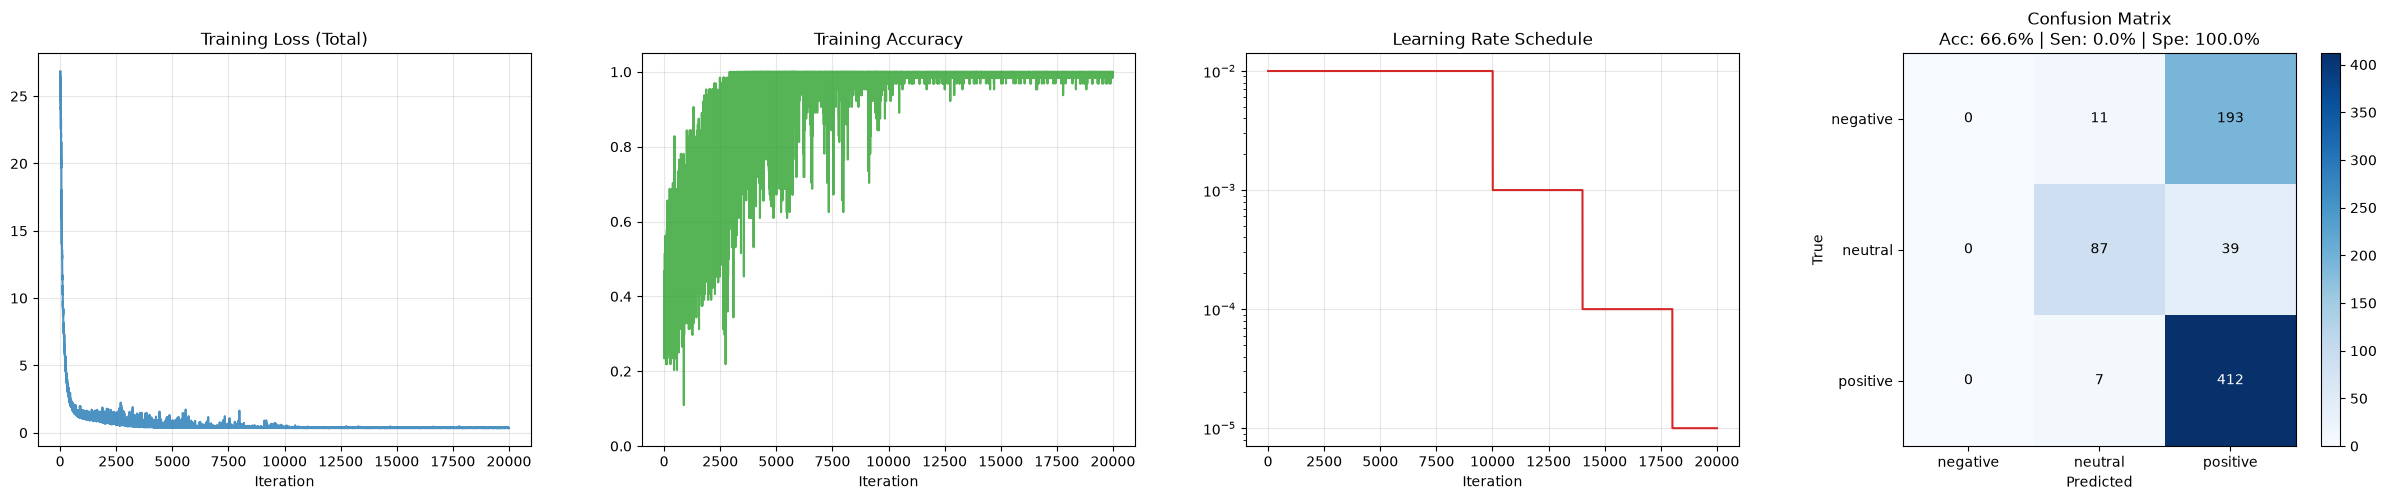

In [5]:
# ==========================================
# 6. EXECUTE TRAINING
# ==========================================
CKPT_PATH = "temporal_cnn_tcn.pt" 
RUN_FULL = True

if RUN_FULL:
    with open(PARTITION_JSON, "r", encoding="utf-8") as f:
        partition = json.load(f)

    train_items = build_index(DATASET_ROOT, partition["TRAIN_SET"])
    test_items = build_index(DATASET_ROOT, partition["TEST_SET"])
    print(f"Train sequences: {len(train_items)} | Test sequences: {len(test_items)}")

    set_seed()
    model = make_model()

    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_tcn = sum(p.numel() for p in model.tcn.parameters() if p.requires_grad)
    print(f"Total parameters: {n_params:,} | TCN parameters: {n_tcn:,}")

    get_batch = make_triplet_batch_fn(train_items, IDS_PER_BATCH, SEQS_PER_ID)

    print(f"\nStarting training: {TOTAL_ITERS} iters, 8x8 batch (split 2x32), LR {TRAIN_LR}")
    history = train(
        model, get_batch, iters=TOTAL_ITERS, lr=TRAIN_LR,
        milestones=MILESTONES, log_every=100, amp=True,
        label_smoothing=LABEL_SMOOTHING, ckpt_path=CKPT_PATH, save_every=5000
    )

    print("\nTraining Complete. Evaluating...")
    evaluate(model, test_items, history)